# AgriStress-500 Dense Patch Token (DPT) Pipeline

Download the dataset -> sample images from one cluster -> tile each image and embed every tile via the PAI embedding API -> run Dense Patch Token evaluation, using the `precisionai.agriemb` package that wires the three sibling projects together:

- [Precision AI Embeddings](https://embeddings.precision.ai/) - hosted image embedding API
- [`agrieval`](https://github.com/Precision-AI-Inc/agrieval) - Dense Patch Token evaluation
- [`agristress-utils`](https://github.com/Precision-AI-Inc/agristress-utils) - dataset download and sampling

DPT scores the per-patch feature-map output of a dense vision backbone — the spatial grid of patch embeddings a model produces before pooling into a single image embedding. That's a different kind of artifact from the pooled, whole-image vectors the hosted PAI embedding API returns directly, so **no dense-feature backbone is wired up to that API** — instead, each sampled image is sliced into a `GRID_HEIGHT` x `GRID_WIDTH` grid of tiles, and every tile is embedded individually through the real API. Every value in the resulting feature map is a genuine embedding — only the tiling scheme is fabricated, not the features. Each tile is a separate `embeddings.create` call, so total API calls scale as `NUM_SAMPLES * GRID_HEIGHT * GRID_WIDTH`: **128 calls** at the 2-image, 8x8 default.

The 8x8 grid is the smallest that keeps the label-aware metrics working. Coarser grids are cheaper, but majority-vote downsampling of the ground-truth masks then resolves every patch to `background` on most clusters, leaving silhouette, Calinski-Harabasz, ARI, NMI and PC1-AUROC all reporting `N/A`.

Validating a ground-truth mask for label-aware metrics requires decoding it at full AgriStress-500 resolution (several megapixels) before downsampling to the patch grid, which costs roughly **15 s per image** — kept small with `NUM_SAMPLES = 2` below. Set `WITH_LABELS = False` to skip masks entirely for an unsupervised-metrics-only result (measured on these two images: 34 s label-aware, 4 s without).

**Setup** (from the repo root, before starting Jupyter):

```bash
pip install -e ".[notebook]"
cp .env.example .env   # fill in PAI_EMBEDDINGS_BASE_URL and PAI_EMBEDDINGS_API_KEY
```

Run all cells top-to-bottom. See the root `README.md` and the standalone `examples/01_download_dataset.py` plus `examples/dpt/01_sample_cluster.py`-`03_run_eval.py` (or the bundled `04_end_to_end.py`) scripts for the non-notebook version.

In [1]:
import io
from pathlib import Path

from IPython.display import Image as IPythonImage
from IPython.display import display
from PIL import Image

from precisionai.agriemb import (
    DEFAULT_GRID_SIZE,
    build_client,
    download,
    embed_patch_tokens,
    run_dpt_evaluation,
    sample_cluster,
    verify_dataset,
)
from precisionai.agriemb.config import DEFAULT_DATASET_DIR, DEFAULT_MODEL, DEFAULT_REPO_ID
from precisionai.agrieval.dpt import print_result
from precisionai.agristress.utils import AgriStressDataset

SEED = 0
CLUSTER = "L1"
NUM_SAMPLES = 2
GRID_HEIGHT, GRID_WIDTH = DEFAULT_GRID_SIZE
WITH_LABELS = True

## 1. Download the dataset

The dataset is ~12 GB across 4950 files and takes 20+ minutes on a fast connection. `verify_dataset` reports which manifest-referenced files are missing, so a complete copy is reused instead of re-walking all 4950 files. The download resumes if it is interrupted, so just re-run this cell.

In [2]:
missing = verify_dataset(DEFAULT_DATASET_DIR)
if missing:
    print(f"{len(missing)} file(s) missing; downloading (~12 GB in full, 20+ minutes)...")
    dataset_dir = download(DEFAULT_DATASET_DIR, repo_id=DEFAULT_REPO_ID)
else:
    dataset_dir = Path(DEFAULT_DATASET_DIR)
    print("Dataset already complete; skipping the download.")

dataset = AgriStressDataset(dataset_dir)
clusters = dataset.list_clusters()

repo_root = Path(DEFAULT_DATASET_DIR).parents[2]
print(f"Dataset  : {dataset_dir.relative_to(repo_root)}")
print(f"Clusters : {len(clusters)}")
print(f"Images   : {len(dataset.list_image_ids())}")

Dataset already complete; skipping the download.
Dataset  : examples/data/agristress
Clusters : 121
Images   : 451


## 2. Sample a cluster

Draws `NUM_SAMPLES` images from cluster `CLUSTER`.

`CLUSTER` defaults to `"L1"`, whose ground-truth masks carry enough foreground to survive downsampling to the patch grid. On most clusters every patch resolves to `background`, which leaves every label-aware metric in step 4 undefined; `run_dpt_evaluation` warns when that happens. Set it to `None` for a random cluster, or to any id from `clusters` above.

In [3]:
cluster, sample = sample_cluster(dataset, cluster=CLUSTER, num_samples=NUM_SAMPLES, seed=SEED)
paths = dataset.resolve_paths(sample)
stems = {Path(image_id).stem: path for image_id, path in paths.items()}

print(f"Cluster {cluster}: sampled {len(sample)} of {len(dataset.list_image_ids(cluster=cluster))} images")
print("\n".join(sample))

Cluster L1: sampled 2 of 5 images
images/L1/pai-QykgTYtO.png
images/L1/pai-OzBTQMjw.png


### Preview the sampled images

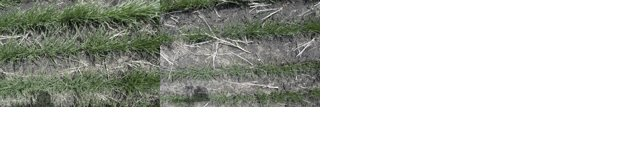

images/L1/pai-QykgTYtO.png
images/L1/pai-OzBTQMjw.png


In [4]:
thumb_size = 160
cols = 4
items = sample
rows = (len(items) + cols - 1) // cols

sheet = Image.new("RGB", (cols * thumb_size, rows * thumb_size), "white")
for i, item_id in enumerate(items):
    thumb = Image.open(paths[item_id]).convert("RGB")
    thumb.thumbnail((thumb_size, thumb_size))
    x, y = (i % cols) * thumb_size, (i // cols) * thumb_size
    sheet.paste(thumb, (x, y))

# JPEG only: `display(sheet)` would embed the same pixels twice (JPEG and PNG),
# which is most of this notebook's committed size.
buffer = io.BytesIO()
sheet.save(buffer, format="JPEG", quality=85)
display(IPythonImage(data=buffer.getvalue(), format="jpeg"))
print("\n".join(items))

## 3. Tile each image and embed every tile

`embed_patch_tokens` slices each image into a `[GRID_HEIGHT, GRID_WIDTH]` grid via `tile_image`, embeds every tile individually through the PAI embedding API, and stacks the real per-tile vectors into a `[P, H, W]` feature map per image (`P` is the embedding dimension the API returns).

In [5]:
client = build_client()
images = embed_patch_tokens(client, stems, grid_size=(GRID_HEIGHT, GRID_WIDTH), model=DEFAULT_MODEL)

n_tiles = len(stems) * GRID_HEIGHT * GRID_WIDTH
print(f"Embedded {n_tiles} tiles into [H={GRID_HEIGHT}, W={GRID_WIDTH}] feature maps")

Embedding:   0%|          | 0/128 [00:00<?, ?batch/s]

Embedding:   1%|          | 1/128 [00:00<02:00,  1.06batch/s]

Embedding:   2%|▏         | 2/128 [00:01<01:12,  1.73batch/s]

Embedding:   2%|▏         | 3/128 [00:01<00:56,  2.22batch/s]

Embedding:   3%|▎         | 4/128 [00:01<00:46,  2.65batch/s]

Embedding:   4%|▍         | 5/128 [00:02<00:40,  3.01batch/s]

... (121 outputs left out)

Embedding:  99%|█████████▉| 127/128 [00:33<00:00,  3.83batch/s]

Embedding: 100%|██████████| 128/128 [00:33<00:00,  3.86batch/s]

Embedding: 100%|██████████| 128/128 [00:33<00:00,  3.78batch/s]

Embedded 128 tiles into [H=8, W=8] feature maps


## 4. Run Dense Patch Token evaluation

`run_dpt_evaluation` pairs the feature maps with the dataset's ground-truth segmentation masks (`masks/`) and class map (`class_map.json`) for label-aware metrics, then evaluates them with `agrieval`'s `run_dpt_image_eval`. With `WITH_LABELS = True` this validates each image's full-resolution mask, costing roughly 15 s per image; set it to `False` above for an unsupervised-metrics-only result (4 s for these two images, versus 34 s label-aware).

In [6]:
result = run_dpt_evaluation(dataset_dir, images, k_values=[5, 10], with_labels=WITH_LABELS)
print_result(result)

k-NN graph:   0%|          | 0/128 [00:00<?, ?item/s]

n_entries: 2
embed_dim: 384
grid     : 8x8
n_patches: 128
k_values : [5, 10]
classes  : ['background', 'Crop | Barley']

── global_metrics ──────────────────────────────────────────────────────
  effective_rank        : 15.2015  (ratio=0.0396  dim=384)
  pca_explained_variance: pc1=0.1502  top_10=0.6763  top_50=0.9503  top_100=0.9946
  pairwise cosine       : mean=0.9734  std=0.0261  (p05=0.9577  p50=0.9781  p95=0.9887)
  centroid cosine       : mean=0.9867  std=0.0180  norm=0.9867
  uniformity            : -0.1018
  mean_patch_smoothness : 0.9814
  mean_outlier_fraction : 0.0000

── per_class ───────────────────────────────────────────────────────────
  background           n_patches=42  effective_rank=7.0978  pc1=0.3090
  Crop | Barley        n_patches=86  effective_rank=14.6291  pc1=0.1538

── knn_confusion ───────────────────────────────────────────────────────
  purity@5  : mean=0.9000  std=0.2179
  purity@10 : mean=0.8727  std=0.2057

── separation ───────────────────────────────